# The third-order aperture-mass statistic: every number, checked

This notebook is the companion of the note
`notes/aperture_mass_statistic/aperture_mass_statistic.tex`.  Each section
computes the numbers one part of the note quotes -- filter properties, toy-model
checks, dataset counts, the fiducial Map3 prediction, the TATT operator split --
and rebuilds every figure of the note through the plot-folder contract
(`plots/<name>/data.json` plus a standalone `plot_<name>.py`).

**How to run it.**  Open it from this directory in an activated Cocoa
environment (`source start_cocoa.sh` from `Cocoa/`), then Kernel - Restart and
Run All.  Sections 2-4 are toy numerics and run in seconds.  Sections 5 and 7
evaluate the project's Cobaya likelihood (about 25 s per model evaluation on a
laptop) and cache their results under the project's `chains/` folder, so a
rerun is fast; delete the `chains/aperture_mass_statistic_*.npz` files to force
a recomputation.

## 1. Set up Python

Paths, imports and the house figure style.  The thread counts are set before
any compiled code loads: OpenMP threads the compiled projection, while BLAS
(numpy's linear algebra) stays at one thread so results do not depend on the
machine's core count.

In [1]:
import os
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the compiled interface is imported (threads=4 below matches it).
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

import json
import subprocess
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Figure style of the whole notebook: the shared plotting functions never
# change rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

# NOTE = this note's folder (the notebook's starting directory); PROJECT =
# projects/des_3pcf, found by walking up to its first example yaml; COCOA =
# the Cocoa root.  The yaml paths are relative to COCOA, so the notebook
# changes there, like the project's EXAMPLE_EVALUATE1.ipynb.
NOTE = Path.cwd().resolve()
PROJECT = NOTE
while not (PROJECT / "EXAMPLE_EVALUATE1.yaml").exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError("Open this notebook from the note folder, "
                                "projects/des_3pcf/notes/aperture_mass_statistic.")
    PROJECT = PROJECT.parent
COCOA = PROJECT.parents[1]
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(COCOA / "external_modules/code/cosmolike_core"))
os.chdir(COCOA)
print("note    :", NOTE)
print("project :", PROJECT)
print("cocoa   :", COCOA)

note    : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/notes/aperture_mass_statistic
project : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf
cocoa   : /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa


Three helpers used everywhere below.

- `report(label, value, note_value)` prints one result: the number this
  notebook computes next to the number the note quotes.  Agreement is read by
  eye, to the digits the note quotes.
- `run_plot(name)` runs the standalone script `plots/<name>/plot_<name>.py`
  (which reads only `plots/<name>/data.json`) and displays the PNG it wrote, so
  every figure shown here is exactly the file the note includes.
- `cached(name, settings, compute)` wraps the expensive likelihood results:
  it reads `chains/aperture_mass_statistic_<name>.npz` if the file exists and
  its stored settings match, computes and writes it otherwise, and raises on a
  settings mismatch instead of silently overwriting.

In [2]:
def report(label, value, note_value):
    """Print one computed number next to the value the note quotes."""
    print(f"{label:58s} notebook: {value}   note: {note_value}")


def run_plot(name):
    """Run plots/<name>/plot_<name>.py and display the PNG it wrote.

    The script reads only its own data.json, so what is shown here is what a
    reader gets by running the script alone (the plot-folder contract).
    """
    folder = NOTE / "plots" / name
    subprocess.run([sys.executable, f"plot_{name}.py"], cwd=folder, check=True)
    display(Image(filename=str(folder / f"{name}.png")))


def cached(name, settings, compute):
    """Read chains/aperture_mass_statistic_<name>.npz or compute and write it.

    Arguments:
      name = the cache's short name (one file per name under chains/).
      settings = a flat dictionary describing what the arrays depend on
        (yaml name, parameter values); stored as a JSON string in the file.
      compute = a function of no arguments returning {key: numpy array}.
    Returns:
      the {key: array} dictionary, from the file or from compute().
    Raises:
      ValueError when the file exists with different settings: delete the
      file to recompute deliberately, never silently overwrite it.
    """
    path = PROJECT / "chains" / f"aperture_mass_statistic_{name}.npz"
    tag = json.dumps(settings, sort_keys=True)
    if path.exists():
        stored = np.load(path, allow_pickle=False)
        if str(stored["settings"]) != tag:
            raise ValueError(f"{path} was written with other settings; "
                             "delete it to recompute.")
        print(f"read {path.name}")
        return {key: stored[key] for key in stored.files if key != "settings"}
    arrays = compute()
    np.savez(path, settings=np.str_(tag), **arrays)
    print(f"wrote {path.name}")
    return arrays

## 2. The compensated filter and the second moment

The note's Section 5 defines the aperture filter (its Eqs. for
$U_R(\theta)$ and $\widehat{U}(\ell R)$) and Section 6 the second moment.
This section checks, numerically:

1. the compensation property $\int d^2\theta\, U_R(\theta) = 0$;
2. the closed Fourier form $\widehat{U}(\ell R) = \frac{1}{2}(\ell R)^2 e^{-(\ell R)^2/2}$ against direct numerical integration of the Bessel transform;
3. the window's peak at $\ell R = \sqrt{2}$ with peak value $1/e$;
4. the white-noise second moment $\langle M_\mathrm{ap}^2 \rangle = A/(8\pi R^2)$.

The filter radii are the four of the DES Y3 measurement, in arcminutes.

In [3]:
from scipy.integrate import quad
from scipy.special import j0

RADII_ARCMIN = np.array([7.0, 14.0, 25.0, 40.0])
ARCMIN = np.pi / (180.0 * 60.0)          # one arcminute in radians
RADII = RADII_ARCMIN * ARCMIN            # the radii in radians


def filter_u(theta, radius):
    """The compensated aperture filter U_R(theta), both in radians."""
    x2 = (theta / radius) ** 2
    return (1.0 - 0.5 * x2) * np.exp(-0.5 * x2) / (2.0 * np.pi * radius ** 2)


def filter_q(theta, radius):
    """The matching tangential-shear weight Q_R(theta)."""
    x2 = (theta / radius) ** 2
    return theta ** 2 * np.exp(-0.5 * x2) / (4.0 * np.pi * radius ** 4)


def filter_uhat(ell, radius):
    """The closed-form Fourier window of U_R."""
    x2 = (ell * radius) ** 2
    return 0.5 * x2 * np.exp(-0.5 * x2)


# 1. Compensation: the 2D integral reduces to 2 pi int theta U dtheta.
# quad integrates to 10 radii, far beyond the Gaussian tail.
radius = RADII[1]                        # R = 14 arcmin as the example
compensation = 2.0 * np.pi * quad(
    lambda theta: theta * filter_u(theta, radius), 0.0, 10.0 * radius)[0]
report("compensation integral of U (R = 14')", f"{compensation:.2e}",
       "0 (below 1e-10)")
assert abs(compensation) < 1e-10

# 2. The closed form against the numerical Bessel (Hankel) transform at a
# few multipoles around the window's peak.
worst = 0.0
for ell in [50.0, 200.0, 350.0, 700.0, 1500.0]:
    numerical = 2.0 * np.pi * quad(
        lambda theta: theta * filter_u(theta, radius) * j0(ell * theta),
        0.0, 10.0 * radius, limit=200)[0]
    closed = filter_uhat(ell, radius)
    worst = max(worst, abs(numerical - closed))
report("closed form vs numerical Bessel transform (max |diff|)",
       f"{worst:.2e}", "below 1e-10")
assert worst < 1e-10

# 3. The peak: on a fine grid of ell R, the maximum sits at sqrt(2) with
# value 1/e.
x = np.linspace(0.5, 2.5, 200001)
window = 0.5 * x ** 2 * np.exp(-0.5 * x ** 2)
report("peak position ell R", f"{x[np.argmax(window)]:.4f}",
       f"sqrt(2) = {np.sqrt(2.0):.4f}")
report("peak value", f"{window.max():.4f}", f"1/e = {np.exp(-1.0):.4f}")

compensation integral of U (R = 14')                       notebook: -6.54e-17   note: 0 (below 1e-10)
closed form vs numerical Bessel transform (max |diff|)     notebook: 5.55e-17   note: below 1e-10
peak position ell R                                        notebook: 1.4142   note: sqrt(2) = 1.4142
peak value                                                 notebook: 0.3679   note: 1/e = 0.3679


In [4]:
# 4. The white-noise second moment: with P(ell) = A constant, the note's
# worked example gives <Map^2> = A / (8 pi R^2).  The quadrature below
# evaluates the general formula int dell ell/(2 pi) A Uhat^2 directly.
amplitude = 1.0
for radius_arcmin, radius in zip(RADII_ARCMIN, RADII):
    numerical = quad(
        lambda ell: ell / (2.0 * np.pi) * amplitude
        * filter_uhat(ell, radius) ** 2,
        0.0, 20.0 / radius, limit=400)[0]
    analytic = amplitude / (8.0 * np.pi * radius ** 2)
    report(f"white-noise <Map^2>, R = {radius_arcmin:g}': numeric/analytic",
           f"{numerical / analytic:.6f}", "1")
    assert abs(numerical / analytic - 1.0) < 1e-8

white-noise <Map^2>, R = 7': numeric/analytic              notebook: 1.000000   note: 1
white-noise <Map^2>, R = 14': numeric/analytic             notebook: 1.000000   note: 1
white-noise <Map^2>, R = 25': numeric/analytic             notebook: 1.000000   note: 1
white-noise <Map^2>, R = 40': numeric/analytic             notebook: 1.000000   note: 1


The filter figure of the note (its `plots/aperture_filter`): the real-space
weight scaled by $R^2$ (the shape is common; the amplitude scales as
$1/R^2$) and the Fourier window for the four radii.

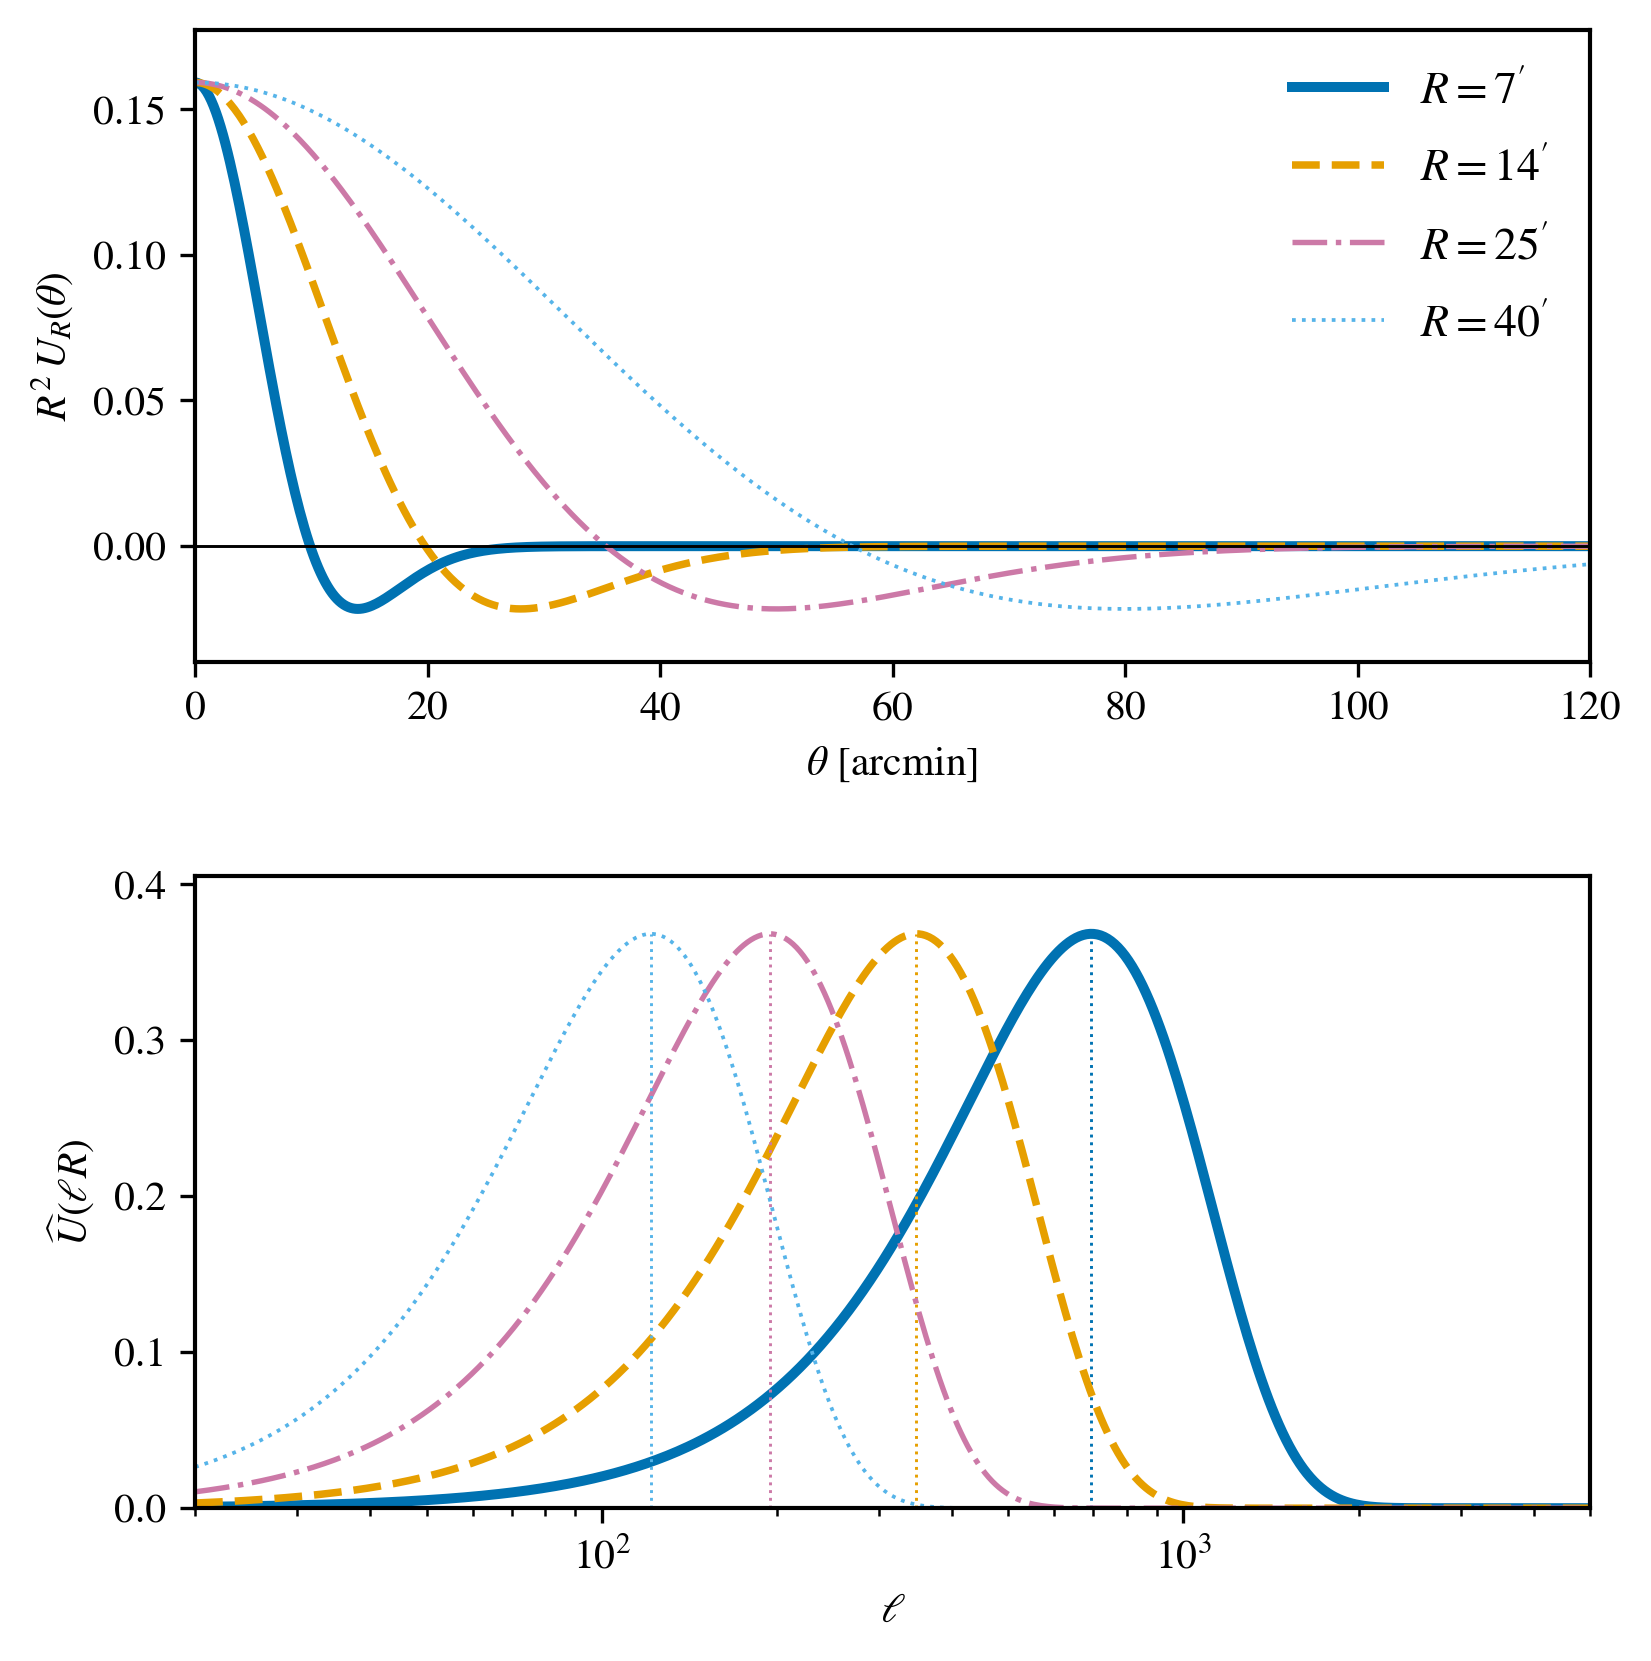

In [5]:
# Export the curves the figure draws, then render it with its standalone
# script.  theta runs to beyond the largest radius's negative trough; ell
# covers the four windows' peaks sqrt(2)/R (about 120 to 700).
theta_arcmin = np.linspace(0.0, 120.0, 601)
u_times_r2 = [filter_u(theta_arcmin * ARCMIN, radius) * radius ** 2
              for radius in RADII]
ell = np.geomspace(20.0, 5000.0, 400)
uhat = [filter_uhat(ell, radius) for radius in RADII]
peak_ell = [float(np.sqrt(2.0) / radius) for radius in RADII]

payload = {
    "about": "The compensated aperture filter of the DES Y3 Map3 "
             "measurement at its four radii: the real-space weight "
             "U_R(theta) times R^2 and the Fourier window Uhat(ell R) = "
             "(ell R)^2/2 exp(-(ell R)^2/2), with each window's peak at "
             "ell = sqrt(2)/R.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 2.",
    "radii_arcmin": RADII_ARCMIN.tolist(),
    "theta_arcmin": theta_arcmin.tolist(),
    "U_times_R2": [curve.tolist() for curve in u_times_r2],
    "ell": ell.tolist(),
    "Uhat": [curve.tolist() for curve in uhat],
    "peak_ell": peak_ell,
}
with open(NOTE / "plots/aperture_filter/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("aperture_filter")

## 3. A simulated convergence map

The note's Sections 3-5 make three claims that a small simulated map can
check end to end:

1. the shear route and the convergence route to the aperture mass agree
   (the note's $Q$-form equation against its $U$-form definition);
2. a constant mass sheet added to $\kappa$ leaves $M_\mathrm{ap}$ unchanged;
3. a Gaussian field has zero third moment, so the skewness of its
   aperture-mass map is consistent with zero.

The map is a periodic Gaussian random field on a $512^2$ grid of a
$10^\circ$ box, with a smooth arbitrary spectrum; the shear field is built
from it with the spin-2 phase $\tilde\gamma = e^{2i\beta} \tilde\kappa$.
Periodicity makes the FFT convolutions exact, so the only error left is the
grid quadrature.

In [6]:
# ----------------------------------------------------------------------
# The Gaussian convergence map and its shear field.
# ----------------------------------------------------------------------
rng = np.random.default_rng(20261123)    # fixed seed: reproducible numbers
npix = 512
box = 10.0 * np.pi / 180.0               # 10 degrees, in radians
pixel = box / npix

# The flat-sky Fourier grid: one angular frequency vector per FFT mode.
freq = 2.0 * np.pi * np.fft.fftfreq(npix, d=pixel)
ell_x, ell_y = np.meshgrid(freq, freq, indexing="ij")
ell_grid = np.hypot(ell_x, ell_y)

# A smooth positive spectrum (arbitrary shape for the checks): flat on
# large scales, falling as a power beyond ell0, cut well inside Nyquist.
ell0 = 400.0
power = 1.0 / (1.0 + (ell_grid / ell0) ** 2) * np.exp(-(ell_grid / 6000.0) ** 2)
power[0, 0] = 0.0                        # a random field has zero mean

# Draw the field in Fourier space: white Gaussian noise times sqrt(P).
# Building the noise as the FFT of a real map keeps kappa exactly real.
white = np.fft.fft2(rng.standard_normal((npix, npix)))
kappa_ell = white * np.sqrt(power / (pixel ** 2 * npix ** 2))
kappa = np.fft.ifft2(kappa_ell).real
kappa_ell = np.fft.fft2(kappa)           # the exact transform of the map

# The spin-2 phase e^{2 i beta}: beta is the polar angle of ell.  The
# ell = 0 mode has no direction; its shear is set to zero.
with np.errstate(invalid="ignore", divide="ignore"):
    phase = ((ell_x + 1j * ell_y) / ell_grid) ** 2
phase[0, 0] = 0.0
gamma = np.fft.ifft2(phase * kappa_ell)  # complex map gamma_1 + i gamma_2
print("kappa map rms:", f"{kappa.std():.4f}")

kappa map rms: 0.4953


In [7]:
# ----------------------------------------------------------------------
# Check 1: the U route (convergence) against the Q route (tangential
# shear) at 16 aperture centers, R = 14 arcmin.
# ----------------------------------------------------------------------
radius = 14.0 * ARCMIN

# U route: filtering is multiplication by Uhat in Fourier space, so one
# FFT gives Map at every pixel at once.
map_u = np.fft.ifft2(filter_uhat(ell_grid, radius) * kappa_ell).real

# Q route: at each chosen center, sum Q(|dtheta|) * gamma_t over the map
# (the direct definition, no FFT).  The minimum-image wrap keeps every
# separation inside the periodic box.
coords = np.arange(npix) * pixel         # pixel-center coordinates
centers = [(i, j) for i in (64, 192, 320, 448) for j in (64, 192, 320, 448)]
worst = 0.0
for (i, j) in centers:
    dx = coords - coords[i]
    dy = coords - coords[j]
    dx = (dx + 0.5 * box) % box - 0.5 * box   # wrap to [-box/2, box/2)
    dy = (dy + 0.5 * box) % box - 0.5 * box
    sep_x, sep_y = np.meshgrid(dx, dy, indexing="ij")
    sep = np.hypot(sep_x, sep_y)
    # The tangential component at separation vector (sep_x, sep_y):
    # gamma_t = -Re[gamma e^{-2 i phi}], with phi the vector's polar angle.
    with np.errstate(invalid="ignore", divide="ignore"):
        phase2 = ((sep_x + 1j * sep_y) / sep) ** 2
    phase2[i, j] = 0.0                       # Q(0) = 0: the center drops out
    gamma_t = -np.real(gamma * np.conj(phase2))
    map_q = np.sum(filter_q(sep, radius) * gamma_t) * pixel ** 2
    worst = max(worst, abs(map_q - map_u[i, j]))
scale = map_u.std()
report("U route vs Q route, max |difference| / rms(Map)",
       f"{worst / scale:.2e}", "below 1e-2")
assert worst / scale < 1e-2

U route vs Q route, max |difference| / rms(Map)            notebook: 2.09e-15   note: below 1e-2


In [8]:
# ----------------------------------------------------------------------
# Check 2: a constant mass sheet drops out.  Adding kappa_0 changes only
# the ell = 0 mode, which the compensated filter multiplies by
# Uhat(0) = 0; the aperture-mass map must not move.
# ----------------------------------------------------------------------
kappa_sheet = kappa + 0.1
map_sheet = np.fft.ifft2(
    filter_uhat(ell_grid, radius) * np.fft.fft2(kappa_sheet)).real
sheet_change = np.max(np.abs(map_sheet - map_u)) / scale
report("mass sheet kappa_0 = 0.1: max |change| / rms(Map)",
       f"{sheet_change:.2e}", "below 1e-12")
assert sheet_change < 1e-12

# ----------------------------------------------------------------------
# Check 3: Gaussian skewness.  The skewness of the aperture-mass map of a
# Gaussian field is zero in the ensemble; one map scatters around zero.
# The scatter estimate splits the map into 16 blocks and uses the spread
# of their skewnesses over sqrt(16).
# ----------------------------------------------------------------------
values = map_u / scale
skewness = np.mean(values ** 3)
blocks = values.reshape(4, 128, 4, 128).transpose(0, 2, 1, 3).reshape(16, -1)
block_skew = np.mean(blocks ** 3, axis=1)
scatter = block_skew.std() / np.sqrt(16.0)
report("skewness of the Gaussian aperture-mass map",
       f"{skewness:+.4f} +/- {scatter:.4f}", "consistent with 0")
assert abs(skewness) < 4.0 * scatter

mass sheet kappa_0 = 0.1: max |change| / rms(Map)          notebook: 1.53e-15   note: below 1e-12
skewness of the Gaussian aperture-mass map                 notebook: +0.0556 +/- 0.0825   note: consistent with 0


## 4. The fiducial point

The note's Section 2 (its Table 1) quotes the `override` block of
`EXAMPLE_EVALUATE1.yaml` and the TATT point of `EXAMPLE_EVALUATE2.yaml`.
This cell prints both from the yamls themselves, and checks that the project
wrappers read the same values.

In [9]:
from cobaya.yaml import yaml_load_file

info1 = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE1.yaml"))
override1 = info1["sampler"]["evaluate"]["override"]
fixed1 = {key: info1["params"][key]
          for key in ("a2", "eta2", "bta", "wa", "mnu")}
fixed1["w0"] = info1["params"]["w0"]["value"]
print("EXAMPLE_EVALUATE1.yaml override (the fiducial point):")
for key, value in override1.items():
    print(f"  {key:10s} = {value}")
print("fixed by the yaml:")
for key, value in fixed1.items():
    print(f"  {key:10s} = {value}")

info2 = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE2.yaml"))
override2 = info2["sampler"]["evaluate"]["override"]
tatt_point = {key: override2[key] for key in ("a2", "eta2", "bta")}
print("EXAMPLE_EVALUATE2.yaml TATT parameters (the note's Eq. for the "
      "TATT point):", tatt_point)

# The wrappers read the same yaml at import; their module constants must
# match the override exactly.
import cosmolike_des_3pcf_notebook_wrappers as nw
assert nw.omegam == override1["omega_m"] and nw.sigma8 == override1["sigma8"]
assert nw.A1_FID == [override1["a1"], override1["eta1"]]
print("wrapper constants match the yaml override")

EXAMPLE_EVALUATE1.yaml override (the fiducial point):
  omega_m    = 0.289
  omega_b    = 0.0463
  h          = 0.722
  ns         = 0.959
  sigma8     = 0.7865548373195137
  a1         = -0.33
  eta1       = 2.81
  m1         = -0.0063
  m2         = -0.0198
  m3         = -0.0241
  m4         = -0.0369
  dz1        = 0
  dz2        = 0
  dz3        = 0
  dz4        = 0
fixed by the yaml:
  a2         = 0.0
  eta2       = 0.0
  bta        = 0.0
  wa         = 0.0
  mnu        = 0.06
  w0         = -1.0
EXAMPLE_EVALUATE2.yaml TATT parameters (the note's Eq. for the TATT point): {'a2': 0.65, 'eta2': 1.69, 'bta': 0.91}
wrapper constants match the yaml override


## 5. The dataset and the fiducial Map3 prediction

The note's Sections 2, 7, 9 and 10 quote the dataset layout: 200 + 200
$\xi_\pm$ rows and 80 Map3 rows, 20 source-bin triplets, the four radii, the
20 side bins from 0.5 to 80 arcmin with the 9-bin scale cut at 8 arcmin,
$\Delta\ln d$, the 63 opening-angle bins and the transform's multipole caps.
This section evaluates the likelihood once at the fiducial point (cached), reads
all of those numbers back, and draws the note's Map3 figure and triangle-
coverage figure.

In [10]:
# One likelihood evaluation at the EXAMPLE_EVALUATE1 fiducial (about
# 25 s), cached under chains/.  The cache stores the joint vector's row
# kinds and the Map3 grid (radii, triplets, values).
nw.configure(threads=4)


def compute_fiducial():
    labels, vector = nw.datavector()
    # A label is "kind:bin1:bin2:bin3:angles..."; the kind is field one.
    kinds = np.array([label.split(":")[0] for label in labels])
    radii, triplets, values = nw.map3()
    return {"kinds": kinds, "vector": vector, "radii": radii,
            "triplets": triplets, "map3": values}


fiducial = cached(
    name="fiducial",
    settings={"yaml": "EXAMPLE_EVALUATE1.yaml", "point": "override"},
    compute=compute_fiducial,
)
kinds = fiducial["kinds"]
report("xi_plus rows", int(np.sum(kinds == "xip")), 200)
report("xi_minus rows", int(np.sum(kinds == "xim")), 200)
report("Map3 rows", int(np.sum(kinds == "map3")), 80)
report("total rows", kinds.size, 480)
report("filter radii [arcmin]", np.round(fiducial["radii"], 6).tolist(),
       "[7, 14, 25, 40]")
report("source-bin triplets", fiducial["triplets"].shape[0], 20)

# The note's combinatorial count: unordered triples with repetition from
# four source bins, C(4 + 3 - 1, 3) = 20.
from math import comb
report("C(4+3-1, 3)", comb(4 + 3 - 1, 3), 20)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


wrote aperture_mass_statistic_fiducial.npz
xi_plus rows                                               notebook: 200   note: 200
xi_minus rows                                              notebook: 200   note: 200
Map3 rows                                                  notebook: 80   note: 80
total rows                                                 notebook: 480   note: 480
filter radii [arcmin]                                      notebook: [7.0, 14.0, 25.0, 40.0]   note: [7, 14, 25, 40]
source-bin triplets                                        notebook: 20   note: 20
C(4+3-1, 3)                                                notebook: 20   note: 20


In [11]:
# The side-bin facts come from the likelihood defaults the plan is built
# with (likelihood/joint_shear.yaml), reproduced with the same arithmetic
# as the likelihood's initialize.
defaults = yaml_load_file(str(PROJECT / "likelihood/joint_shear.yaml"))
theta_min = defaults["theta_min_arcmin"]
theta_max = defaults["theta_max_arcmin"]
ntheta = defaults["ntheta"]
cut = defaults["theta_lower_cut_arcmin"]
edges = np.exp(np.linspace(np.log(theta_min), np.log(theta_max), ntheta + 1))
kept = edges[:-1][edges[:-1] >= cut]
dlnt = float(np.log(edges[1] / edges[0]))
report("side bins (theta_min, theta_max, ntheta)",
       (theta_min, theta_max, ntheta), "(0.5, 80, 20)")
report("kept side bins (lower edge >= cut)", kept.size, 9)
report("log side-bin width Delta ln d", f"{dlnt:.4f}",
       "ln(160)/20 = 0.2538")
report("opening-angle bins (phi_bins)", defaults["phi_bins"], 63)
report("transform multipole caps (map_lmax, map_mmax)",
       (defaults["map_lmax"], defaults["map_mmax"]), "(20, 20)")

side bins (theta_min, theta_max, ntheta)                   notebook: (0.5, 80.0, 20)   note: (0.5, 80, 20)
kept side bins (lower edge >= cut)                         notebook: 9   note: 9
log side-bin width Delta ln d                              notebook: 0.2538   note: ln(160)/20 = 0.2538
opening-angle bins (phi_bins)                              notebook: 63   note: 63
transform multipole caps (map_lmax, map_mmax)              notebook: (20, 20)   note: (20, 20)


The fiducial Map3 figure of the note (its `plots/map3_fiducial`): the
prediction against the radius for four representative triplets, scaled by a
power of ten chosen here.  Bins are numbered 1 to 4, low to high redshift.

scale: 10^-9;  drawn triplets: ['(1, 1, 1)', '(1, 1, 4)', '(2, 3, 4)', '(4, 4, 4)']


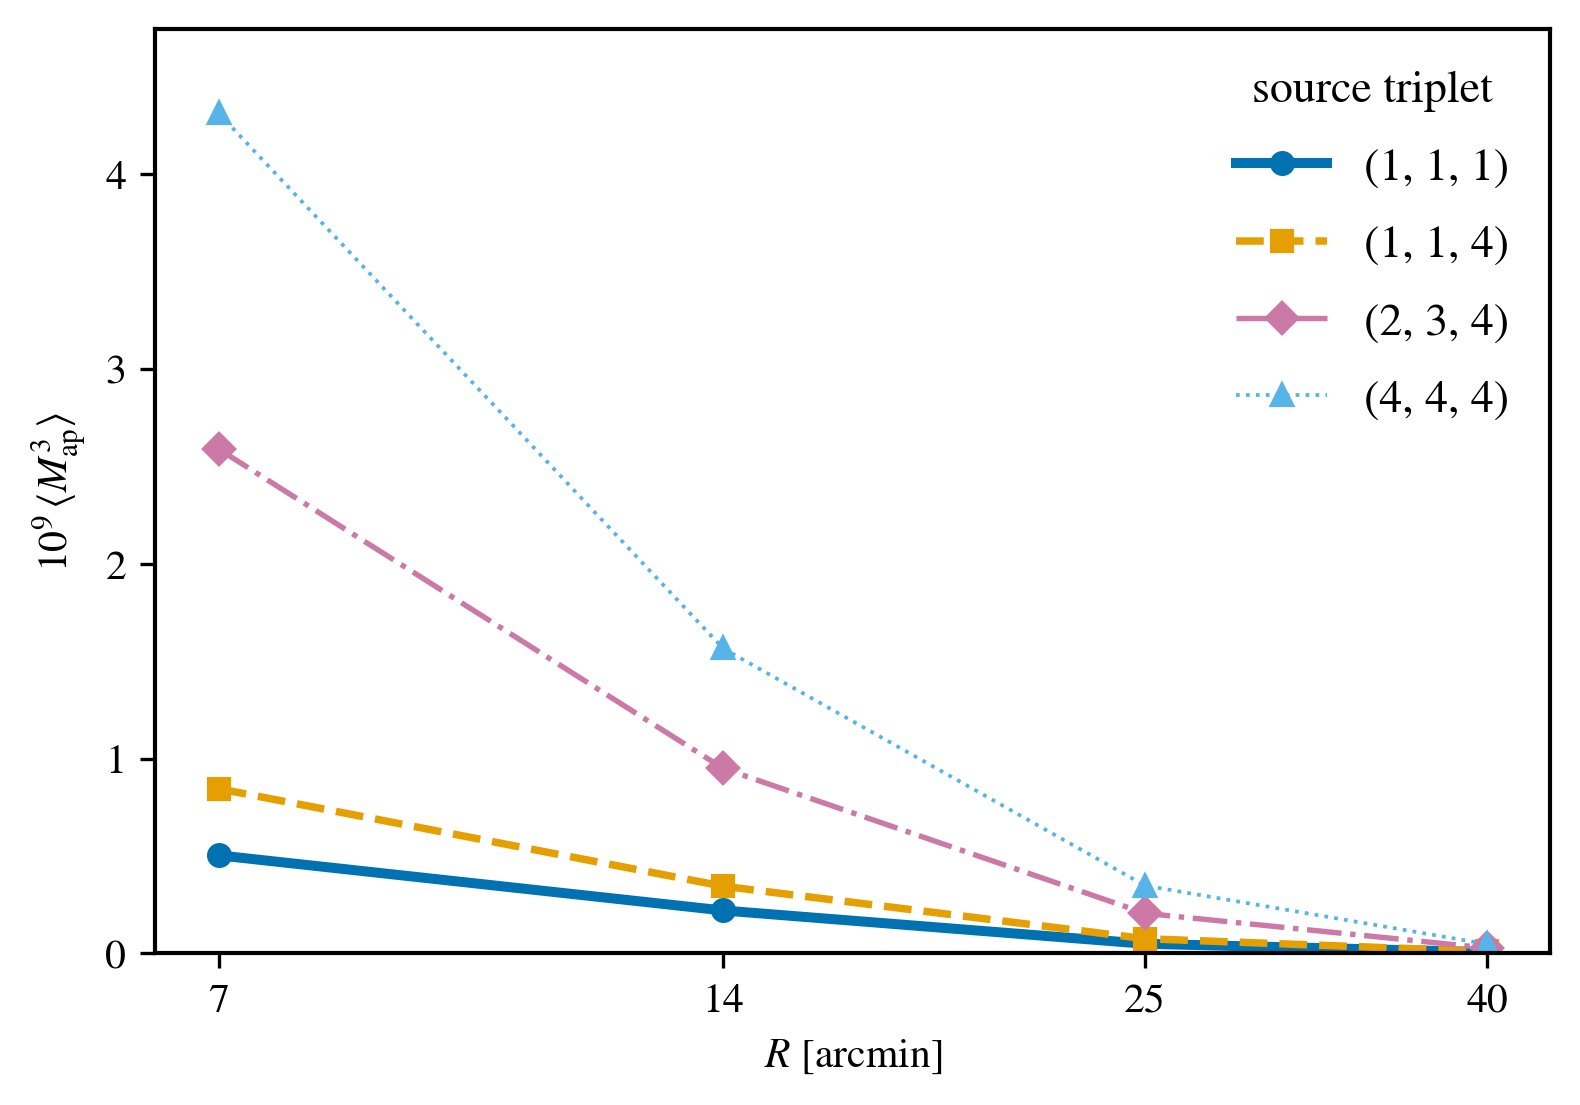

In [12]:
# Pick four triplets that span the range: the lowest and highest
# auto-triplets and two mixed ones.  The dataset's triplets are zero-based.
drawn = [(0, 0, 0), (0, 0, 3), (1, 2, 3), (3, 3, 3)]
triplets = [tuple(int(b) for b in row) for row in fiducial["triplets"]]
rows = [triplets.index(t) for t in drawn]
values = fiducial["map3"].T[rows]        # map3 is [nradius, ntriplet]

# One shared power of ten brings the largest curve to order one.
exponent = int(np.ceil(-np.log10(np.max(np.abs(values)))))
scaled = values * 10.0 ** exponent
labels = ["(" + ", ".join(str(b + 1) for b in t) + ")" for t in drawn]
print("scale: 10^-%d;  drawn triplets:" % exponent, labels)

payload = {
    "about": "Map3 of the des_3pcf likelihood at the EXAMPLE_EVALUATE1 "
             "fiducial, for four source-bin triplets (bins numbered 1-4, "
             "low to high redshift), times 10^%d.  Written by the export "
             "cell of aperture_mass_statistic.ipynb, Section 5, from "
             "nw.map3()." % exponent,
    "radii_arcmin": fiducial["radii"].tolist(),
    "triplet_labels": labels,
    "scaled_values": scaled.tolist(),
    "ylabel": r"$10^{%d}\, \langle M_{\mathrm{ap}}^3 \rangle$" % exponent,
}
with open(NOTE / "plots/map3_fiducial/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("map3_fiducial")

The triangle-coverage figure of the note (its `plots/triangle_coverage`):
the side plane of the SAS grid, the kept block and the aperture radii.

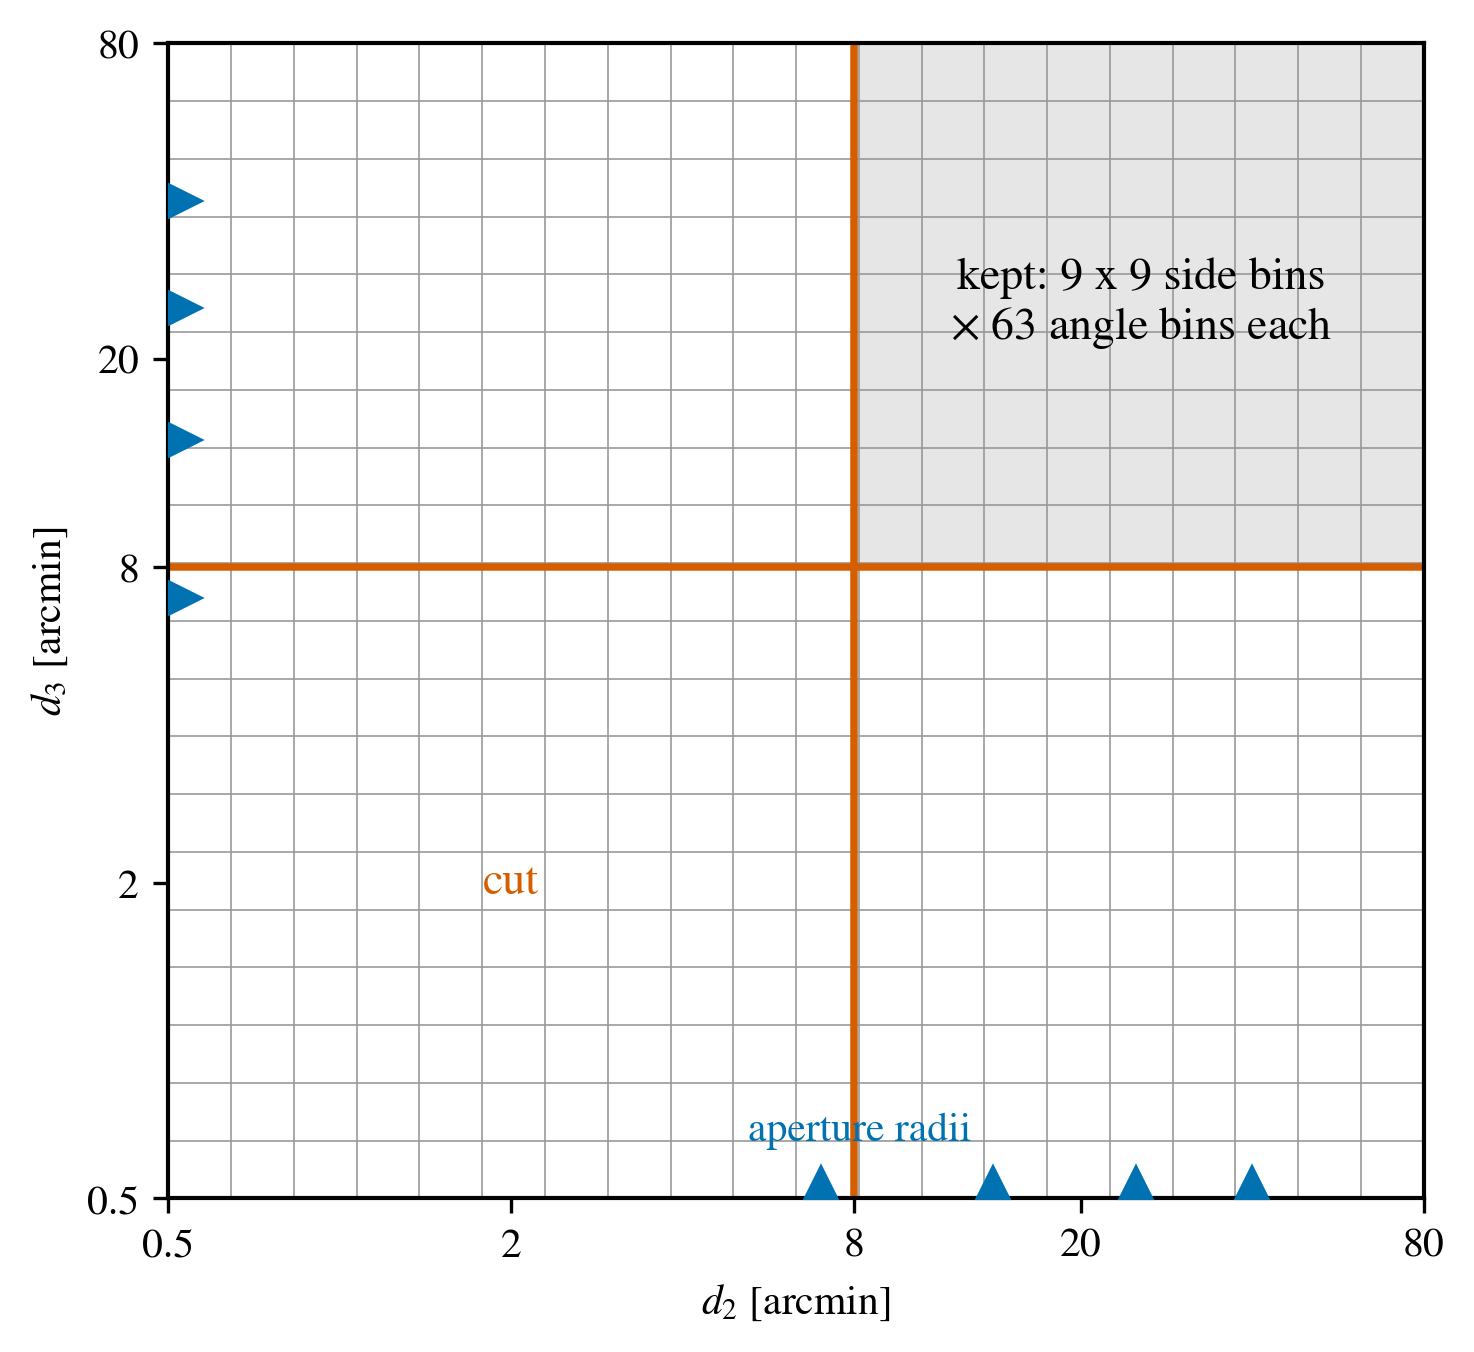

In [13]:
payload = {
    "about": "The side plane (d2, d3) of the SAS triangle grid of the DES "
             "Y3 Map3 rows: 20 logarithmic side bins from 0.5 to 80 arcmin, "
             "the 9 x 9 block kept by the 8 arcmin lower-edge cut (each "
             "pair with 63 opening-angle bins), and the four aperture "
             "radii.  Written by the export cell of "
             "aperture_mass_statistic.ipynb, Section 5, from the "
             "likelihood/joint_shear.yaml keys.",
    "edges_arcmin": edges.tolist(),
    "cut_arcmin": cut,
    "kept_lower_edges_arcmin": kept.tolist(),
    "radii_arcmin": fiducial["radii"].tolist(),
    "phi_bins": defaults["phi_bins"],
}
with open(NOTE / "plots/triangle_coverage/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("triangle_coverage")

## 6. Measurement arithmetic

The note's Section 10 quotes the DES Y3 measurement's multipole count: the
LogMultipole estimator with cutoff $n_\mathrm{max} = 100$ keeps the
multipoles $-100, \ldots, +100$.  The likelihood's own transform truncates
at the `map_mmax` printed above; the difference is one of the note's open
items.

In [14]:
n_max = 100
report("LogMultipole multipole values, 2 n_max + 1", 2 * n_max + 1, 201)
report("likelihood transform cap map_mmax", defaults["map_mmax"], 20)

LogMultipole multipole values, 2 n_max + 1                 notebook: 201   note: 201
likelihood transform cap map_mmax                          notebook: 20   note: 20


## 7. The TATT operator split

The note's Section 11 describes the intrinsic-alignment theory and its
figure shows the operator split of `nw.map3_components()` at the TATT point
of `EXAMPLE_EVALUATE2.yaml`: five physical operators (gravity-only lensing,
linear alignment, density weighting, tidal torquing, velocity shear) by the
eight placements GGG ... III, for the lowest-redshift triplet, where the
alignment terms are largest.  The velocity-shear amplitude stays zero, as in
the likelihood.  The evaluation plus the component projections are cached.

In [15]:
nw.configure(yaml="EXAMPLE_EVALUATE2.yaml", threads=4)


def compute_components():
    result = nw.map3_components(
        triplets=[[0, 0, 0]],
        A2=[tatt_point["a2"], tatt_point["eta2"]],
        BTA=tatt_point["bta"],
    )
    components = result["components"]
    print("alignment record used:", result["ia"])
    return {
        "operators": np.array(components["operators"]),
        "placements": np.array(components["placements"]),
        "values": components["values"],
        "total": components["total"],
        "closure": components["closure"],
        "prediction": result["prediction"],
        "radii": result["rows"].angles[:, 0] / ARCMIN,
    }


split = cached(
    name="components",
    settings={"yaml": "EXAMPLE_EVALUATE2.yaml", "triplet": [0, 0, 0],
              "a2": tatt_point["a2"], "eta2": tatt_point["eta2"],
              "bta": tatt_point["bta"], "velocity_shear": 0.0},
    compute=compute_components,
)
print("operators :", split["operators"].tolist())
print("placements:", split["placements"].tolist())
print("radii     :", np.round(split["radii"], 3).tolist())
# closure = (sum of the 5 x 8 pieces) - (the separately computed total):
# the split must add up to the ordinary prediction.
closure = np.max(np.abs(split["closure"]) / np.abs(split["total"]))
report("operator-split closure, max |sum - total| / |total|",
       f"{closure:.2e}", "below 1e-6")
assert closure < 1e-6

[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 4.05931 s  (1 evaluations)


[camb.transfers] Average evaluation time for camb.transfers: 0.496115 s  (1 evaluations)


[camb] Average evaluation time for camb: 0.271777 s  (1 evaluations)


[bihalofit] Average evaluation time for bihalofit: 0.0158629 s  (1 evaluations)


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


alignment record used: {'a1': -0.33, 'eta1': 2.81, 'a2': 0.65, 'eta2': 1.69, 'bta': 0.91, 'c1rho': 0.01389, 'zpivot': 0.62, 'power_mode': 2, 'ct': 0.0, 'fb': 0.0, 'feedback_amplitude': 0.0, 'ct_mode': 0}
wrote aperture_mass_statistic_components.npz
operators : ['gravity', 'linear_alignment', 'density_weighting', 'tidal_torque', 'velocity_shear']
placements: ['GGG', 'GGI', 'GIG', 'IGG', 'GII', 'IIG', 'IGI', 'III']
radii     : [7.0, 14.0, 25.0, 40.0]
operator-split closure, max |sum - total| / |total|        notebook: 6.53e-15   note: below 1e-6


velocity-shear contribution at C_t = 0, max |value|        notebook: 0.00e+00   note: 0
linear alignment     / gravity: [0.1088, 0.0927, 0.0866, 0.0854]
density weighting    / gravity: [0.0009, 0.0012, 0.0008, -0.0006]
tidal torquing       / gravity: [0.0052, 0.007, 0.0043, -0.0034]


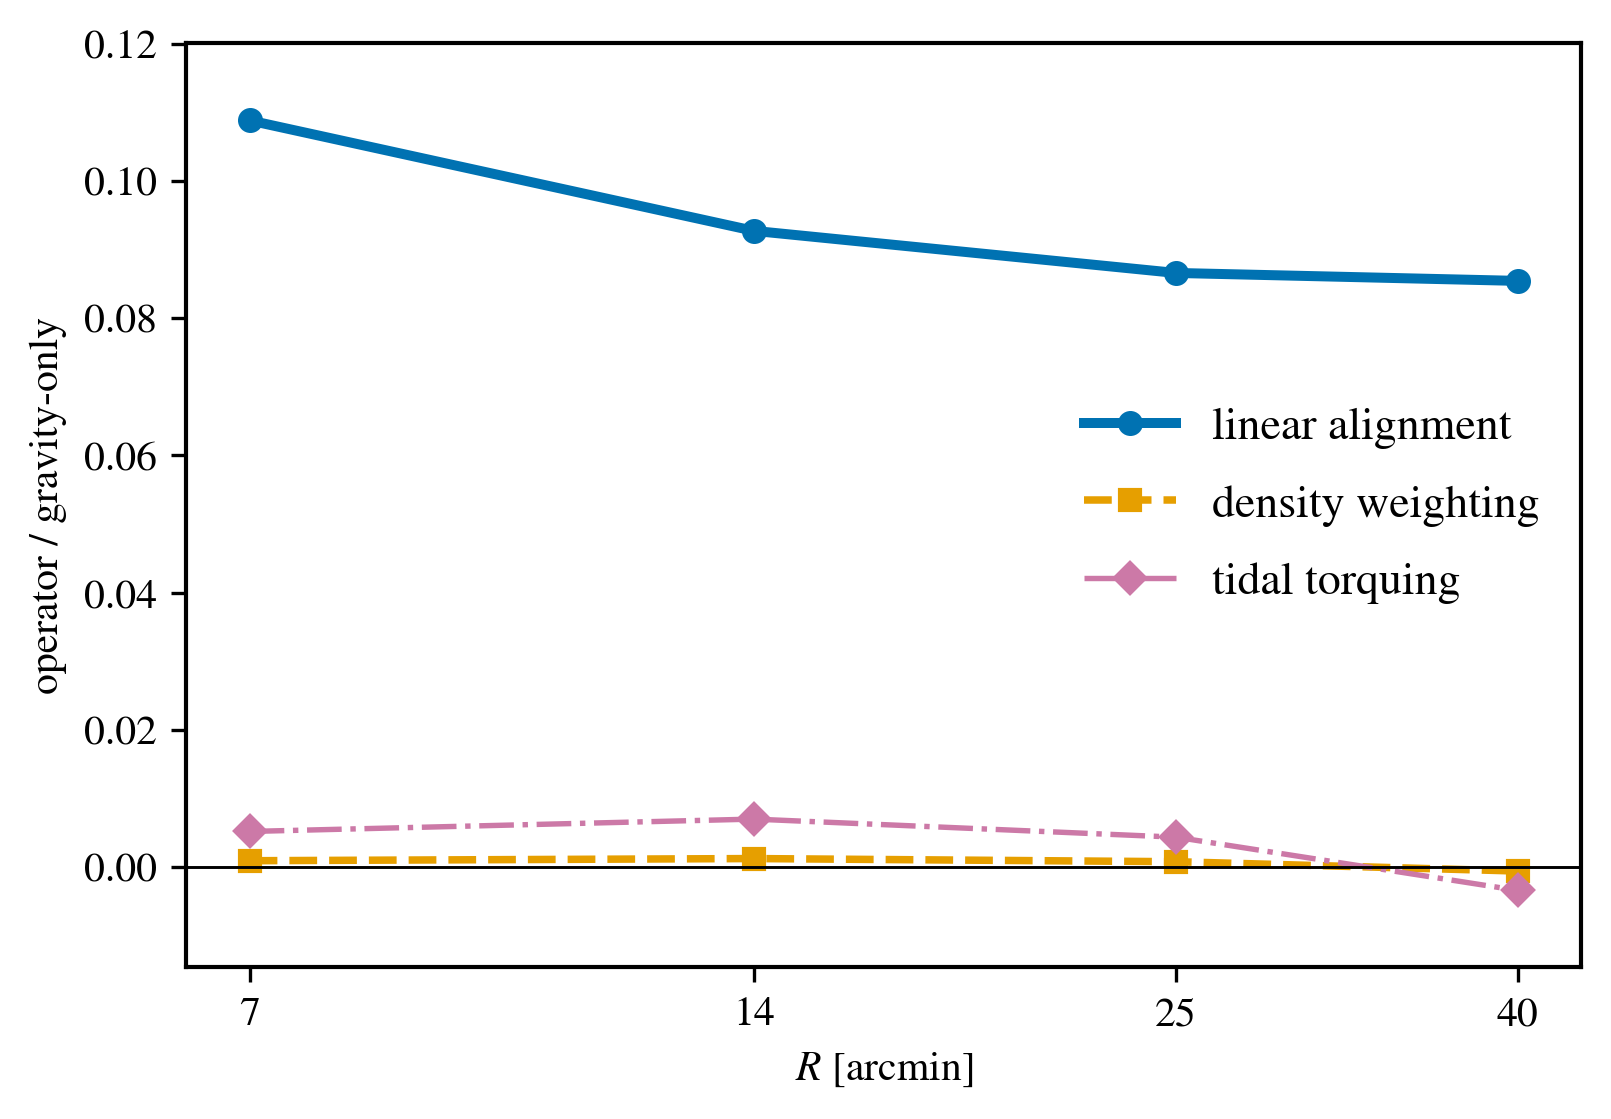

In [16]:
# Each operator's contribution, summed over its eight placements, as a
# fraction of the gravity-only term at the same radius.  The rows arrive
# in dataset order; sort them by radius for the plot.
order = np.argsort(split["radii"])
radii = split["radii"][order]
summed = split["values"].sum(axis=1)[:, order]     # [5, nradius]
gravity = summed[0]
ratios = summed[1:4] / gravity                     # skip gravity and the
velocity = summed[4]                               # zero velocity shear
report("velocity-shear contribution at C_t = 0, max |value|",
       f"{np.max(np.abs(velocity)):.2e}", "0")
names = ["linear alignment", "density weighting", "tidal torquing"]
for name, curve in zip(names, ratios):
    print(f"{name:20s} / gravity:", np.round(curve, 4).tolist())

payload = {
    "about": "The intrinsic-alignment operator split of the Map3 rows of "
             "the lowest-redshift source triplet at the TATT point of "
             "EXAMPLE_EVALUATE2.yaml (a2 = %.2f, eta2 = %.2f, bta = %.2f): "
             "each operator summed over its eight placements, divided by "
             "the gravity-only term, with C_t = 0.  Written by the export "
             "cell of aperture_mass_statistic.ipynb, Section 7, from "
             "nw.map3_components()." % (tatt_point["a2"],
                                        tatt_point["eta2"],
                                        tatt_point["bta"]),
    "radii_arcmin": radii.tolist(),
    "operator_names": names,
    "ratio_to_gravity": ratios.tolist(),
    "ylabel": "operator / gravity-only",
}
with open(NOTE / "plots/map3_operators/data.json", "w") as stream:
    json.dump(payload, stream)
run_plot("map3_operators")

## 8. The numbers the note quotes

Every number quoted in `aperture_mass_statistic.tex` is printed above:

- Section 2 (fiducial table, TATT point, data layout): cells of Sections 4
  and 5;
- Section 5 (compensation, window peak $\sqrt{2}$ and $1/e$): Section 2,
  first cell;
- Section 6 (white-noise $\langle M_\mathrm{ap}^2 \rangle = A/(8\pi R^2)$):
  Section 2, second cell;
- Sections 3-5 sanity checks (shear route, mass sheet, Gaussian skewness):
  Section 3;
- Section 7 (the 20 triplets, 80 rows): Section 5;
- Sections 9-10 (side bins, cut, $\Delta\ln d$, angle bins, multipole caps,
  201 measurement multipoles): Sections 5 and 6;
- Section 11 (TATT point, operator split, closure): Section 7.

The figures `aperture_filter`, `map3_fiducial`, `triangle_coverage` and
`map3_operators` are rebuilt by their export cells; each
`plots/<name>/plot_<name>.py` redraws its figure from `data.json` alone.